# 02 – Limpieza, preprocesado y split por grupos

# 1.Importación librerías

In [1]:
import os
import re
import json
import shutil
import hashlib
import itertools
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

try:
    from tqdm.auto import tqdm
except ImportError:                       # si no hay tqdm, seguimos sin barra de progreso
    tqdm = lambda x, **k: x

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
N_HILOS = min(8, os.cpu_count() or 4)

# 2.Configuración

In [2]:
# --- Rutas ---
RAIZ   = Path(r'D:\Vector IA\data\raw')
SALIDA = Path(r'D:\Vector IA\data\processed')

# --- Preprocesado (igual para TODAS las fuentes) ---
TAM = 256                  # lado de las imágenes procesadas (cuadradas). Luego se pueden reducir a 128 o 224
MODO = 'estirar'           # 'estirar' | 'centro' | 'padding'
CALIDAD_JPEG = 90          # misma compresión para todas las fuentes
LIMPIAR_SALIDA = True      # borra la carpeta SALIDA antes de generar (solo esa carpeta)

# --- Clases y fuentes: (clase, fuente, ruta, rol) ---
#   rol 'modelo'  -> se reparte en entrenamiento / validacion / test
#   rol 'externo' -> test externo: no se toca durante el entrenamiento
FUENTES = [
    ('aegypti',    'kaggle',   RAIZ / 'aegypti',                                                'modelo'),
    ('albopictus', 'kaggle',   RAIZ / 'albopictus',                                             'modelo'),
    ('culex',      'ieee',     RAIZ / 'culex',                                                  'modelo'),
    ('aegypti',    'mendeley', RAIZ / 'Original Images Mendeley' / 'Aedes Aegypti',            'externo'),
    ('culex',      'mendeley', RAIZ / 'Original Images Mendeley' / 'Culex Quinquefasciatus',   'externo'),
]

# Documentado para el informe: qué se dejó fuera y por qué
EXCLUIDAS = {
    'anopheles (Mendeley)':   'solo 9 imágenes y no está en el enunciado',
    'aedes (IEEE)':           'género sin especie confirmada; no se puede etiquetar como aegypti/albopictus',
    'Mosquito Images Augmented': 'copias aumentadas de los originales: provocarían leakage',
}

CLASES = sorted({c for c, _, _, _ in FUENTES})
print('Clases:', CLASES)

# Comprobaciones de seguridad
for clase, fuente, ruta, rol in FUENTES:
    assert ruta.exists(), f'No se encontró la carpeta ({clase} / {fuente}): {ruta}'
assert RAIZ not in SALIDA.parents and SALIDA != RAIZ, 'SALIDA no puede estar dentro de RAIZ'

Clases: ['aegypti', 'albopictus', 'culex']


**¿Por qué `MODO = 'estirar'`?** En las fotos de Kaggle el mosquito aparece en cualquier parte del encuadre (a veces cerca del borde).
Un recorte central podría cortarlo. Estirar a cuadrado deforma un poco (4:3 → 1:1) pero conserva todo el mosquito.
Si prefieres otro, cambia `MODO` y revisa la verificación visual de la sección 5.

# 3.Inventario de imágenes

In [3]:
EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

registros = []
for clase, fuente, ruta, rol in FUENTES:
    for f in ruta.rglob('*'):
        if f.suffix.lower() in EXTS:
            registros.append({'ruta_origen': str(f),
                              'archivo': f.name,
                              'subcarpeta': str(f.parent.relative_to(ruta)),
                              'clase': clase,
                              'fuente': fuente,
                              'rol': rol})
df = pd.DataFrame(registros)
print('Total de imágenes:', len(df))
pd.crosstab([df['clase'], df['fuente']], df['rol'])

Total de imágenes: 5432


rol                  externo  modelo
clase      fuente                   
aegypti    kaggle          0    2403
           mendeley       15       0
albopictus kaggle          0    2400
culex      ieee            0     594
           mendeley       20       0

# 4.Eliminar duplicados exactos

Calculamos el MD5 de cada archivo. Si un mismo archivo aparece con **clases distintas** se descarta por completo (etiqueta ambigua).
Si es un duplicado dentro de la misma clase, se conserva una sola copia. Como las fuentes de rol `modelo` van primero en la lista,
si una imagen del test externo coincide con una de entrenamiento, se elimina la del externo (así el externo es realmente externo).

In [4]:
def md5_archivo(ruta):
    h = hashlib.md5()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

with ThreadPoolExecutor(max_workers=N_HILOS) as ex:
    df['md5'] = list(tqdm(ex.map(md5_archivo, df['ruta_origen']), total=len(df), desc='MD5'))

# 1) Mismo archivo en clases distintas -> ambiguo, se descarta
n_clases = df.groupby('md5')['clase'].transform('nunique')
print('Imágenes con etiqueta ambigua (descartadas):', int((n_clases > 1).sum()))
df = df[n_clases == 1]

# 2) Duplicados dentro de la misma clase -> se deja una copia
es_dup = df.duplicated('md5', keep='first')
print('Duplicados exactos eliminados:', int(es_dup.sum()))
display(df[es_dup].groupby(['clase', 'fuente']).size().rename('eliminadas').to_frame())
df = df[~es_dup].reset_index(drop=True)
print('Imágenes tras limpiar:', len(df))

Imágenes con etiqueta ambigua (descartadas): 0
Duplicados exactos eliminados: 25


,,eliminadas
clase,fuente,
aegypti,kaggle,3
culex,ieee,22


Imágenes tras limpiar: 5407


# 5.Preprocesado unificado

Todas las imágenes (de cualquier fuente) pasan por **exactamente el mismo pipeline**: corregir rotación EXIF → RGB →
ajustar a `TAM`×`TAM` → guardar como JPEG con la misma calidad. Así se reduce (aunque no se elimina del todo) la huella de cada fuente
y las épocas de entrenamiento serán mucho más rápidas que leyendo fotos de 4K.

In [5]:
if LIMPIAR_SALIDA and SALIDA.exists():
    shutil.rmtree(SALIDA)
STAGING = SALIDA / '_staging'
STAGING.mkdir(parents=True, exist_ok=True)

def ajustar(im):
    if MODO == 'estirar':
        return im.resize((TAM, TAM), Image.LANCZOS)
    if MODO == 'centro':
        return ImageOps.fit(im, (TAM, TAM), Image.LANCZOS, centering=(0.5, 0.5))
    if MODO == 'padding':
        return ImageOps.pad(im, (TAM, TAM), Image.LANCZOS, color=(128, 128, 128))
    raise ValueError(f'MODO desconocido: {MODO}')

def procesar(args):
    origen, destino = args
    try:
        with Image.open(origen) as im:
            im.draft('RGB', (TAM * 2, TAM * 2))          # lectura rápida de JPEG grandes
            im = ImageOps.exif_transpose(im).convert('RGB')
            ajustar(im).save(destino, 'JPEG', quality=CALIDAD_JPEG)
        return 'ok'
    except Exception as e:
        return f'error: {e}'

df['id'] = np.arange(len(df))
df['nombre_proc'] = [f'{i:05d}_{f}.jpg' for i, f in zip(df['id'], df['fuente'])]
df['ruta_stag'] = [str(STAGING / n) for n in df['nombre_proc']]

with ThreadPoolExecutor(max_workers=N_HILOS) as ex:
    df['estado'] = list(tqdm(ex.map(procesar, zip(df['ruta_origen'], df['ruta_stag'])),
                             total=len(df), desc='Procesando'))

errores = df[df['estado'] != 'ok']
print('Imágenes con error (descartadas):', len(errores))
if len(errores):
    display(errores[['ruta_origen', 'estado']].head())
df = df[df['estado'] == 'ok'].drop(columns='estado').reset_index(drop=True)
print('Imágenes procesadas:', len(df))

Imágenes con error (descartadas): 0
Imágenes procesadas: 5407


## 5.1 Verificación visual

Revisa que el mosquito siga siendo visible tras el preprocesado, sobre todo en Kaggle (donde es pequeño).

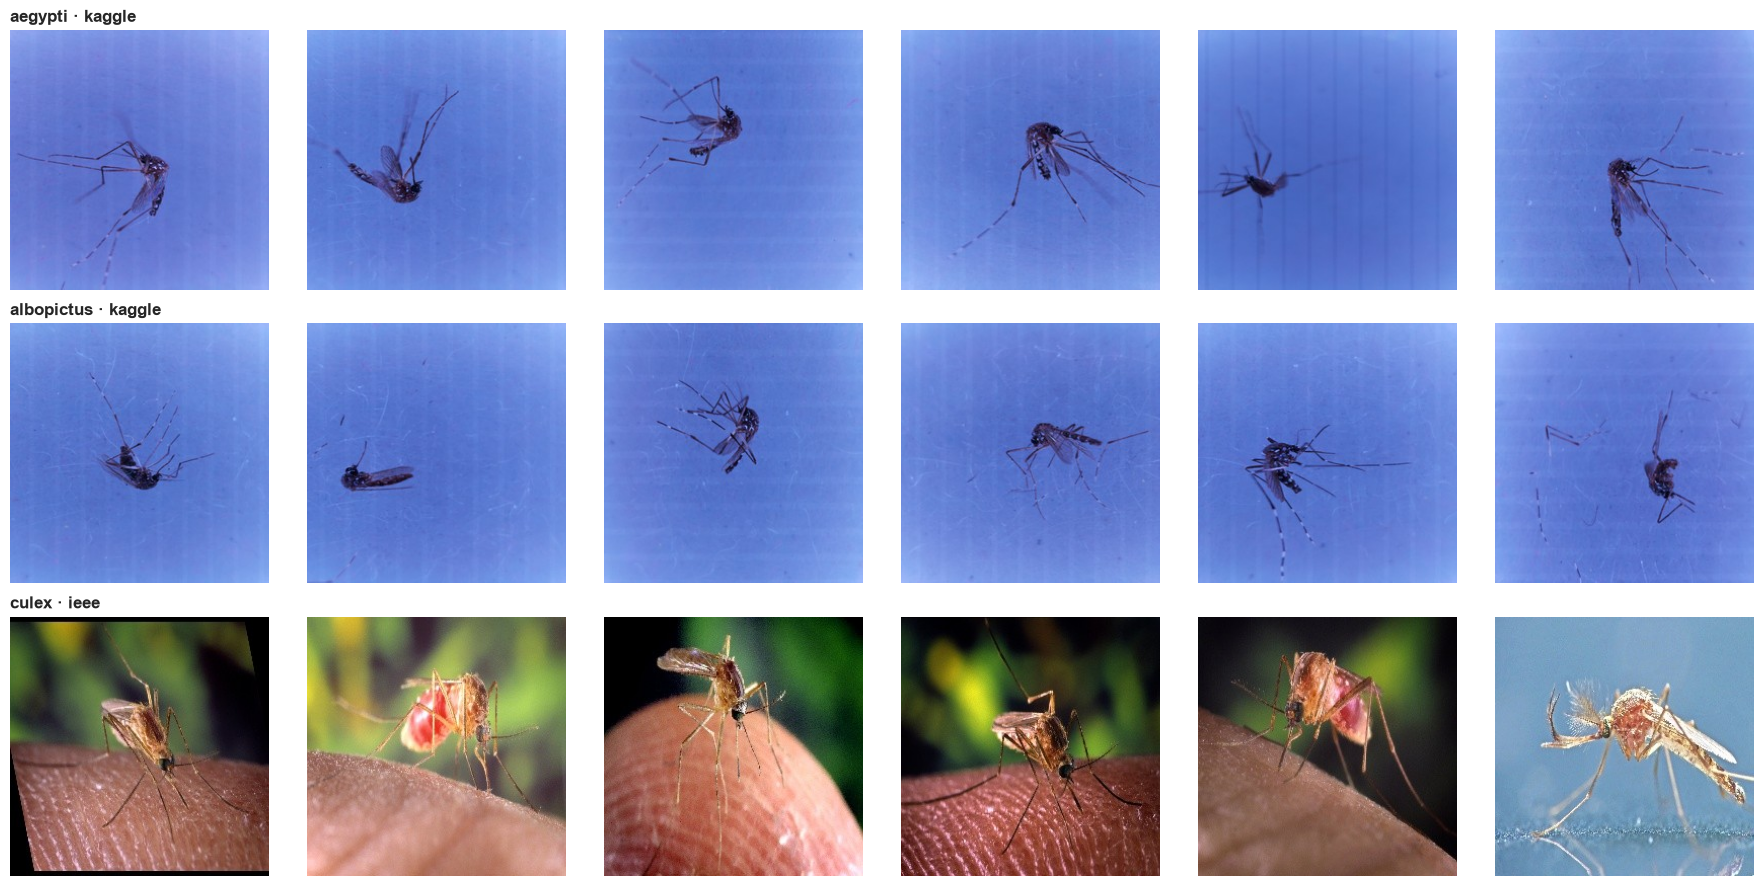

In [6]:
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
combos = [('aegypti', 'kaggle'), ('albopictus', 'kaggle'), ('culex', 'ieee')]
for fila, (c, fu) in enumerate(combos):
    muestra = df[(df.clase == c) & (df.fuente == fu)].sample(6, random_state=SEED)
    for col, ruta in enumerate(muestra['ruta_stag']):
        axes[fila, col].imshow(Image.open(ruta))
        axes[fila, col].axis('off')
        if col == 0:
            axes[fila, col].set_title(f'{c} · {fu}', loc='left', fontweight='bold')
plt.tight_layout()
plt.show()

# 6.Agrupar imágenes parecidas (evitar leakage)

Si dos fotos del mismo espécimen caen una en entrenamiento y otra en test, el modelo "recuerda" el espécimen y el F1 sale inflado.
Por eso se forman **grupos** y el split repartirá grupos completos. Los grupos se construyen con dos pistas:

1. **Nombre de archivo** (Kaggle): `aegypti100a`, `aegypti100b`, `aegypti100c` → mismo grupo `aegypti100`.
2. **Hash perceptual dHash** (IEEE, donde no conocemos la estructura de nombres): imágenes casi idénticas dentro de la misma clase.

## 6.1 Grupos por nombre de archivo

In [7]:
def grupo_por_nombre(clase, fuente, archivo):
    stem = Path(archivo).stem.lower()
    m = re.match(r'^(.*?\d+)[a-z]?$', stem)         # quita una letra final (a, b, c...)
    base = m.group(1) if m else stem
    return f'{clase}|{fuente}|{base}'

df['grupo_nombre'] = [grupo_por_nombre(c, f, a) for c, f, a in zip(df['clase'], df['fuente'], df['archivo'])]

tam_grupos = df.groupby(['fuente', 'grupo_nombre']).size().rename('tamaño').reset_index()
print('Distribución del tamaño de grupo por fuente (n° de grupos con cada tamaño):')
display(tam_grupos.groupby(['fuente', 'tamaño']).size().unstack(fill_value=0))

Distribución del tamaño de grupo por fuente (n° de grupos con cada tamaño):


tamaño,1,4,12,15,16
fuente,,,,,
ieee,572,0,0,0,0
kaggle,3,1,1,3,296
mendeley,35,0,0,0,0


En Kaggle deberías ver que casi todos los grupos tienen **3 imágenes** (a, b, c). Si en cambio ves casi todos de tamaño 1,
el patrón de nombres es distinto al supuesto y hay que ajustar la expresión regular.

## 6.2 Hash perceptual (dHash 16×16 = 256 bits)

In [8]:
def dhash(ruta, lado=16):
    with Image.open(ruta) as im:
        g = np.asarray(im.convert('L').resize((lado + 1, lado), Image.LANCZOS), dtype=np.float32)
    return (g[:, 1:] > g[:, :-1]).flatten()

with ThreadPoolExecutor(max_workers=N_HILOS) as ex:
    H = np.stack(list(tqdm(ex.map(dhash, df['ruta_stag']), total=len(df), desc='dHash')))
print('Matriz de hashes:', H.shape)

Matriz de hashes: (5407, 256)


## 6.3 Validar los grupos de Kaggle

Comprobamos si las imágenes de un mismo grupo (a, b, c) son **realmente más parecidas** entre sí que dos imágenes al azar de la misma clase.
Si las distancias dentro del grupo son claramente menores, la hipótesis de "mismo espécimen" se sostiene.

Distancia de Hamming (de 256 bits) - mediana dentro del grupo: 51 | al azar: 51


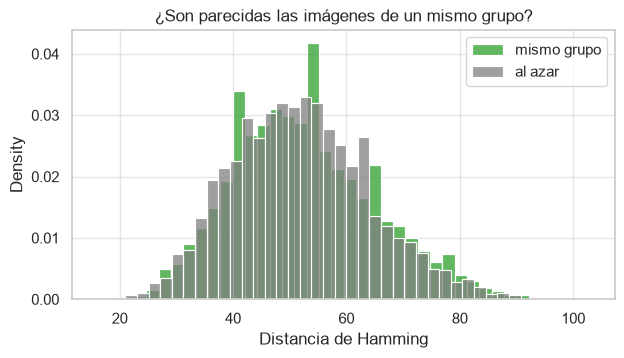

In [10]:
rng = np.random.default_rng(SEED)
kg = df[df.fuente == 'kaggle']

dentro = []
for _, idx in kg.groupby('grupo_nombre').indices.items():
    pos = kg.index[idx]
    if len(pos) > 1:
        dentro += [int((H[i] != H[j]).sum()) for i, j in itertools.combinations(pos, 2)]

azar = []
for clase in kg['clase'].unique():
    pos = kg.index[kg['clase'] == clase].to_numpy()
    for _ in range(1500):
        i, j = rng.choice(pos, 2, replace=False)
        if df.at[i, 'grupo_nombre'] != df.at[j, 'grupo_nombre']:
            azar.append(int((H[i] != H[j]).sum()))

if dentro:
    print(f'Distancia de Hamming (de 256 bits) - mediana dentro del grupo: {np.median(dentro):.0f} | al azar: {np.median(azar):.0f}')
    fig, ax = plt.subplots(figsize=(7, 3.5))
    sns.histplot(dentro, bins=40, color='tab:green', label='mismo grupo', stat='density', ax=ax)
    sns.histplot(azar, bins=40, color='tab:gray', label='al azar', stat='density', ax=ax)
    ax.legend(); ax.set_xlabel('Distancia de Hamming'); ax.set_title('¿Son parecidas las imágenes de un mismo grupo?')
    plt.show()
else:
    print('No hay grupos de más de 1 imagen en Kaggle: revisa la expresión regular de la sección 6.1.')

## 6.4 Construir los grupos finales

Con *union-find* se fusionan: (a) imágenes con el mismo `grupo_nombre` y (b) imágenes de **IEEE** con hash casi idéntico dentro de la misma clase.
El hash no se aplica a Kaggle porque su fondo azul uniforme puede dar falsas coincidencias; ahí confiamos en los nombres.

In [11]:
HASH_EN = {'ieee'}          # fuentes donde se agrupa también por hash
HASH_UMBRAL = 10            # <= 10 bits de 256 distintos = casi idénticas

padre = np.arange(len(df))
def find(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]
        x = padre[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        padre[rb] = ra

# (a) por nombre
for _, idx in df.groupby('grupo_nombre').indices.items():
    for i in idx[1:]:
        union(idx[0], i)

# (b) por hash, dentro de la misma clase y fuente
Hf = H.astype(np.float32)
for clase in CLASES:
    for fuente in HASH_EN:
        idx = np.where((df['clase'] == clase) & (df['fuente'] == fuente))[0]
        if len(idx) < 2:
            continue
        A = Hf[idx]
        d = A @ (1 - A).T + (1 - A) @ A.T
        ii, jj = np.where(np.triu(d <= HASH_UMBRAL, k=1))
        for a, b in zip(ii, jj):
            union(idx[a], idx[b])

df['grupo'] = [find(i) for i in range(len(df))]
tam = df.groupby('grupo').size()
print(f'Grupos: {len(tam)} | imágenes: {len(df)} | tamaño máximo de grupo: {tam.max()}')
display(df.groupby(['clase', 'fuente'])['grupo'].nunique().rename('n_grupos').to_frame())
if tam.max() > 30:
    print('AVISO: hay un grupo muy grande. Baja HASH_UMBRAL para evitar fusionar imágenes que no son del mismo espécimen.')

Grupos: 593 | imágenes: 5407 | tamaño máximo de grupo: 17


n_grupos
clase      fuente            
aegypti    kaggle         153
           mendeley        15
albopictus kaggle         151
culex      ieee           254
           mendeley        20

## 6.5 Casi-duplicados entre clases (versión estricta)

Con el dHash de 256 bits (mucho más exigente que el hash anterior) buscamos imágenes casi idénticas con **etiquetas distintas**. Lo esperado es cerca de 0.

In [12]:
mod = np.where(df['rol'] == 'modelo')[0]
Hm = Hf[mod]
cod = pd.factorize(df.loc[mod, 'clase'])[0]
cruzadas = 0
for ini in range(0, len(mod), 1000):
    fin = min(ini + 1000, len(mod))
    d = Hm[ini:fin] @ (1 - Hm).T + (1 - Hm[ini:fin]) @ Hm.T
    cruzadas += int(((d <= HASH_UMBRAL) & (cod[ini:fin, None] != cod[None, :])).any(axis=1).sum())
print(f'Imágenes con casi-duplicado de OTRA clase (umbral {HASH_UMBRAL}/256): {cruzadas}')

Imágenes con casi-duplicado de OTRA clase (umbral 10/256): 0


# 7.Split por grupos (entrenamiento / validación / test)

Se reparte ~70 % / 15 % / 15 % con `StratifiedGroupKFold`: mantiene la proporción de clases **y** nunca separa un grupo.
Las imágenes de Mendeley (rol `externo`) quedan aparte como test externo.

In [13]:
from sklearn.model_selection import StratifiedGroupKFold

mod = df[df['rol'] == 'modelo']
grupos_por_clase = mod.groupby('clase')['grupo'].nunique()
assert (grupos_por_clase >= 8).all(), f'Muy pocos grupos en alguna clase:\n{grupos_por_clase}'

# 1) test ≈ 1/7 (14,3 %)
sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
pos_trval, pos_test = next(sgkf1.split(mod, mod['clase'], mod['grupo']))
trval = mod.iloc[pos_trval]

# 2) validación ≈ 1/6 del resto (14,3 % del total)
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
pos_tr, pos_val = next(sgkf2.split(trval, trval['clase'], trval['grupo']))

df['split'] = None
df.loc[mod.index[pos_test], 'split'] = 'test'
df.loc[trval.index[pos_val], 'split'] = 'validacion'
df.loc[trval.index[pos_tr], 'split'] = 'entrenamiento'
df.loc[df['rol'] == 'externo', 'split'] = 'externo'

# Comprobación: ningún grupo en más de un split
g_split = df[df['rol'] == 'modelo'].groupby('grupo')['split'].nunique()
assert (g_split == 1).all(), 'Hay grupos repartidos en más de un split'
print('OK: ningún grupo está en más de un split.\n')

orden = ['entrenamiento', 'validacion', 'test', 'externo']
tabla = pd.crosstab(df['split'], df['clase']).reindex(orden)
tabla['total'] = tabla.sum(axis=1)
display(tabla)
display((pd.crosstab(df['split'], df['clase'], normalize='index').reindex(orden) * 100).round(1))
display(pd.crosstab(df['split'], df['fuente']).reindex(orden))

OK: ningún grupo está en más de un split.



clase,aegypti,albopictus,culex,total
split,,,,
entrenamiento,1712,1712,409,3833
validacion,337,352,81,770
test,351,336,82,769
externo,15,0,20,35


clase,aegypti,albopictus,culex
split,,,
entrenamiento,44.7,44.7,10.7
validacion,43.8,45.7,10.5
test,45.6,43.7,10.7
externo,42.9,0.0,57.1


fuente,ieee,kaggle,mendeley
split,,,
entrenamiento,409,3424,0
validacion,81,689,0
test,82,687,0
externo,0,0,35


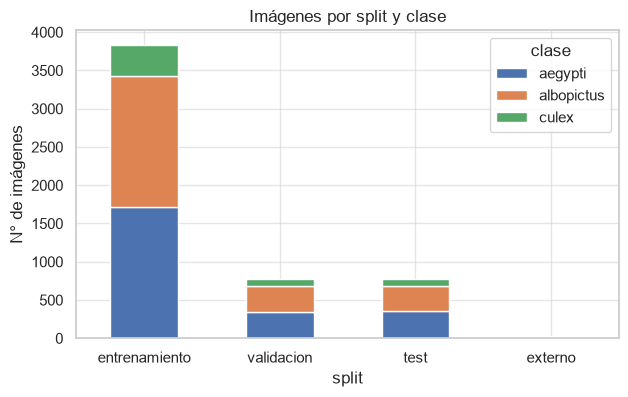

In [14]:
pd.crosstab(df['split'], df['clase']).reindex(orden).plot(kind='bar', stacked=True, figsize=(7, 4), rot=0)
plt.title('Imágenes por split y clase'); plt.ylabel('N° de imágenes')
plt.show()

# 8.Guardar imágenes organizadas y manifiesto

In [15]:
rutas_finales = []
for _, r in df.iterrows():
    destino = SALIDA / r['split'] / r['clase']
    destino.mkdir(parents=True, exist_ok=True)
    nuevo = destino / r['nombre_proc']
    shutil.move(r['ruta_stag'], nuevo)
    rutas_finales.append(str(nuevo))
df['ruta_proc'] = rutas_finales
shutil.rmtree(STAGING, ignore_errors=True)

cols = ['ruta_proc', 'split', 'clase', 'fuente', 'grupo', 'rol', 'md5', 'ruta_origen', 'archivo']
df[cols].to_csv(SALIDA / 'manifest.csv', index=False)

# Pesos de clase calculados SOLO con entrenamiento
from sklearn.utils.class_weight import compute_class_weight
y_tr = df.loc[df['split'] == 'entrenamiento', 'clase']
pesos = compute_class_weight('balanced', classes=np.array(CLASES), y=y_tr)
class_weights = {i: float(w) for i, w in enumerate(pesos)}

config = {'clases': CLASES, 'class_weights': class_weights, 'tam': TAM, 'modo': MODO,
          'calidad_jpeg': CALIDAD_JPEG, 'seed': SEED, 'excluidas': EXCLUIDAS}
(SALIDA / 'config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')

print('Guardado en:', SALIDA)
print('Índices de clase:', {c: i for i, c in enumerate(CLASES)})
print('class_weights   :', {k: round(v, 3) for k, v in class_weights.items()})

Guardado en: D:\Vector IA\data\processed
Índices de clase: {'aegypti': 0, 'albopictus': 1, 'culex': 2}
class_weights   : {0: 0.746, 1: 0.746, 2: 3.124}


# 9.Prueba de atajos (¿puede una clase adivinarse sin mirar el mosquito?)

Entrenamos un modelo muy simple (Random Forest) con **solo 6 números por imagen**: brillo, contraste, color medio RGB y tamaño del archivo.
No ve ninguna forma de mosquito. Si aun así acierta mucho, esas pistas (que dependen de la fuente) son un atajo para la CNN.

> **Cómo usarlo:** la CNN debe superar con claridad este baseline para demostrar que aprende mosquitos y no fuentes.

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report

def rasgos(ruta):
    with Image.open(ruta) as im:
        arr = np.asarray(im.convert('RGB').resize((64, 64)), dtype=np.float32) / 255
    g = arr.mean(axis=2)
    return [arr[..., 0].mean(), arr[..., 1].mean(), arr[..., 2].mean(), g.mean(), g.std(),
            os.path.getsize(ruta) / 1024]

with ThreadPoolExecutor(max_workers=N_HILOS) as ex:
    X = np.array(list(tqdm(ex.map(rasgos, df['ruta_proc']), total=len(df), desc='Rasgos')))
y = df['clase'].to_numpy()
tr, va, exm = (df['split'] == 'entrenamiento').to_numpy(), (df['split'] == 'validacion').to_numpy(), (df['split'] == 'externo').to_numpy()

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1).fit(X[tr], y[tr])
print(f'F1 macro (validación, 3 clases): {f1_score(y[va], rf.predict(X[va]), average="macro"):.3f}')
print(f'F1 macro (externo Mendeley)    : {f1_score(y[exm], rf.predict(X[exm]), average="macro"):.3f}')

# Comparación justa: aegypti vs albopictus, ambas de Kaggle (misma fuente, mismo estilo de foto)
kg = (df['fuente'] == 'kaggle').to_numpy()
rf2 = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1).fit(X[tr & kg], y[tr & kg])
print(f'F1 macro (aegypti vs albopictus, solo Kaggle): {f1_score(y[va & kg], rf2.predict(X[va & kg]), average="macro"):.3f}')

F1 macro (validación, 3 clases): 0.866
F1 macro (externo Mendeley)    : 0.364
F1 macro (aegypti vs albopictus, solo Kaggle): 0.795


**Cómo leerlo**
- **F1 alto en 3 clases** (cercano a 1): hay atajos fuertes por fuente. Es esperable, porque *culex* viene de IEEE y *aegypti/albopictus* de Kaggle.
- **F1 ≈ 0,5 en aegypti vs albopictus (Kaggle):** esa tarea no tiene atajo; ahí la CNN tendría que aprender de verdad la especie.
- **F1 bajo en el externo:** el baseline de atajos no generaliza a otra fuente, así que el externo es una prueba exigente y honesta.

# 10.Vista previa de los conjuntos finales

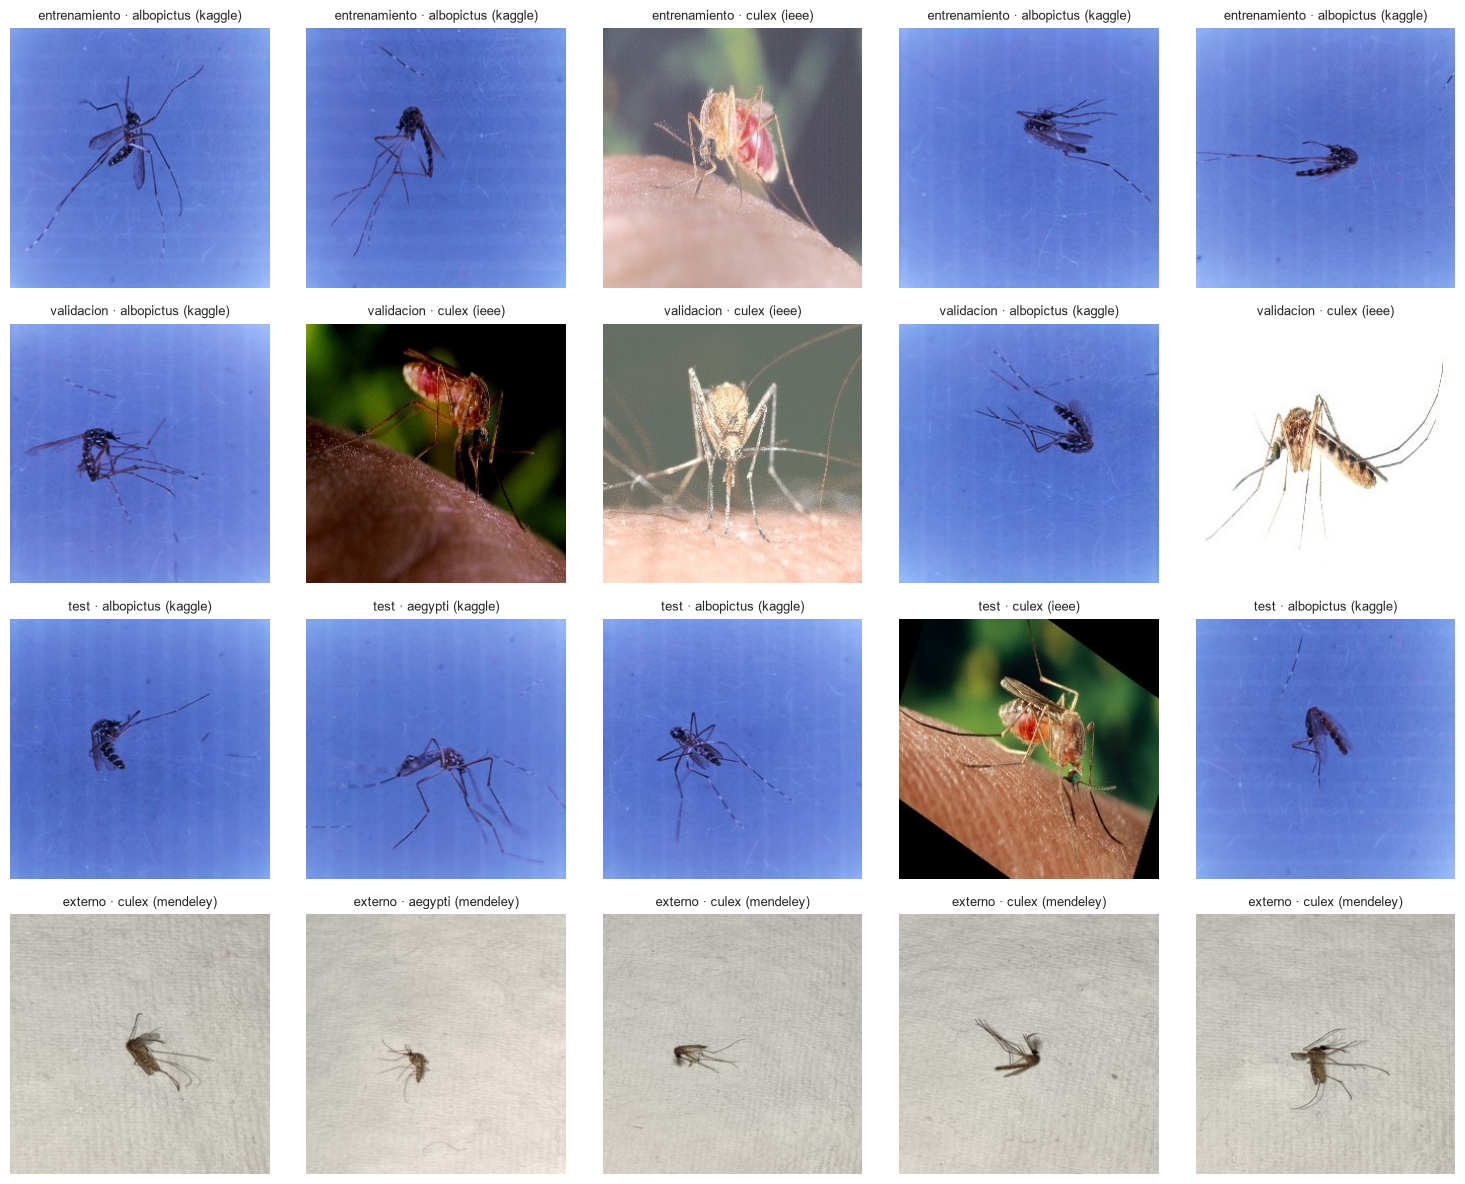

In [17]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for fila, sp in enumerate(orden):
    sub = df[df['split'] == sp]
    muestra = sub.sample(min(5, len(sub)), random_state=SEED)
    for col in range(5):
        ax = axes[fila, col]; ax.axis('off')
        if col < len(muestra):
            r = muestra.iloc[col]
            ax.imshow(Image.open(r['ruta_proc']))
            ax.set_title(f"{sp} · {r['clase']} ({r['fuente']})", fontsize=9)
plt.tight_layout()
plt.show()